# 06 Regression: how much to lend (Part B4 to B5)

**Spec (Section 1.4).** Target `log1p(Total_Amount)`, trained on **repaid** loans only, so the model learns "the amount borrowers like this have shown they can repay". Inputs exclude anything computed from the amount being predicted (`log_amount`, `amount_per_day_log`, `amount_vs_prev_mean`). Validation uses the Section 4 temporal folds, restricted to repaid loans. Amounts are in KES; a GHS equivalent uses the 2023 average exchange rates from `economic_indicators.csv`.

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import set_seed, FIGURES, DATA_PROCESSED, ECON_CSV
from src import models as M, validation as V
set_seed()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
rp = feat[(feat.split == "train") & (feat.target == 0)].reset_index(drop=True)
rp["log_amount_target"] = np.log1p(rp.Total_Amount)

fx = pd.read_csv(ECON_CSV).query("Indicator.str.startswith('Official exchange rate')").set_index("Country")["YR2023"]
KES_TO_GHS = fx["Ghana"] / fx["Kenya"]
print(f"Repaid loans: {len(rp):,} | 2023 rates: {fx['Kenya']:.2f} KES/USD, {fx['Ghana']:.2f} GHS/USD -> 1 KES = {KES_TO_GHS:.4f} GHS")
print("Inputs:", M.REG_FEATURES + ["loan_type", "lender_id"])

Repaid loans: 65,438 | 2023 rates: 139.85 KES/USD, 11.02 GHS/USD -> 1 KES = 0.0788 GHS
Inputs: ['duration', 'Lender_portion_Funded', 'n_lenders', 'is_new', 'n_prev_loans', 'n_prev_resolved', 'n_prev_defaults', 'prev_default_rate', 'has_resolved_history', 'n_active_loans', 'active_amount_log', 'days_since_last_loan', 'days_since_last_default', 'prev_amount_mean_log', 'prev_amount_max_log', 'prev_duration_mean', 'n_prev_lenders', 'disb_month', 'disb_weekday', 'disb_day', 'disb_month_end', 'loan_type', 'lender_id']


## 6.1 Candidates

| Model | Notes |
|---|---|
| Mean baseline | Predicts the training mean of log amount |
| Persistence baseline | Predicts the borrower's mean past amount (training mean if no history). A strong, model-free rule |
| Linear regression, raw terms | Ordinary least squares on standardised features |
| Linear regression | Same, but `duration` and `prev_duration_mean` on a log scale |
| Ridge (α = 10) | L2-regularised version |
| LightGBM | Gradient-boosted trees |

All models are wrapped in `ClippedRegressor`, which caps predictions at the smallest and largest amount repaid in the training fold: NkwaPay should never suggest a loan larger than any it has seen repaid.

In [2]:
cands = {"mean": M.mean_reg(), "linreg_raw_terms": M.linreg(log_terms=()), "linreg": M.linreg(),
         "ridge": M.ridge(), "lgbm": M.lgbm_reg()}
oof, folds = {}, {}
for name, model in cands.items():
    p, fid, f = V.cross_validate_reg(model, rp, M.inputs(M.REG_FEATURES), V.temporal(rp))
    oof[name], folds[name] = p, f
ok = fid >= 0
late = fid[ok] >= 3
# Persistence: the borrower's own average, with the training-fold mean for first loans
pers = np.full(len(rp), np.nan)
for i, (a, b) in enumerate(V.temporal(rp)):
    pers[b] = rp.prev_amount_mean_log.iloc[b].fillna(rp.log_amount_target.iloc[a].mean()).to_numpy()
oof["persistence"] = pers
yl = rp.log_amount_target.to_numpy()[ok]
print(f"OOF repaid loans: {ok.sum():,} (boom {(~late).sum():,}, shifted {late.sum():,})")

OOF repaid loans: 39,239 (boom 36,696, shifted 2,543)


In [3]:
order = ["mean", "persistence", "linreg_raw_terms", "linreg", "ridge", "lgbm"]
def row(n, mask):
    return V.regression_errors(yl[mask], oof[n][ok][mask])
board = pd.concat({reg: pd.DataFrame({n: row(n, m) for n in order}).T
                   for reg, m in [("pooled", np.ones_like(late)), ("boom", ~late), ("shifted", late)]}, names=["regime", "model"])
board["mae_ghs"] = board.mae_amt * KES_TO_GHS
board["median_ae_ghs"] = board.median_ae_amt * KES_TO_GHS
board.to_csv(FIGURES.parent / "06_regression_board.csv")
board[["rmse_log", "mae_log", "rmse_amt", "mae_amt", "median_ae_amt", "mae_ghs", "median_ae_ghs", "within_25pct"]].round(3)

rmse_log  mae_log    rmse_amt    mae_amt  \
regime  model                                                        
pooled  mean                 1.231    0.955   52134.940   9313.206   
        persistence          0.811    0.548   41817.469   6216.409   
        linreg_raw_terms     0.767    0.556   43672.757   6525.757   
        linreg               0.761    0.552   39753.983   5969.938   
        ridge                0.759    0.550   39415.812   5907.178   
        lgbm                 0.761    0.545   47396.137   6488.878   
boom    mean                 1.192    0.941   30848.206   7254.424   
        persistence          0.809    0.552   29635.701   5052.890   
        linreg_raw_terms     0.772    0.562   25916.674   5121.301   
        linreg               0.766    0.558   25915.683   4791.877   
        ridge                0.765    0.558   25504.484   4746.932   
        lgbm                 0.759    0.550   27997.903   4777.500   
shifted mean                 1.693    1.161  167952.783  39021.838   
        persistence          0.846    0.486  119620.737  23006.222   
        linreg_raw_terms     0.695    0.471  140491.212  26792.339   
        linreg               0.678    0.462  121218.471  22969.594   
        ridge                0.654    0.430  120772.172  22649.769   
        lgbm                 0.792    0.483  152809.437  31184.400   

                          median_ae_amt   mae_ghs  median_ae_ghs  within_25pct  
regime  model                                                                   
pooled  mean                   3460.922   733.915        272.733         0.200  
        persistence            1880.792   489.876        148.213         0.382  
        linreg_raw_terms       1967.070   514.254        155.012         0.330  
        linreg                 1962.321   470.453        154.638         0.333  
        ridge                  1929.863   465.507        152.080         0.338  
        lgbm                   1839.090   511.347        144.927         0.345  
boom    mean                   3427.000   571.675        270.060         0.195  
        persistence            1842.886   398.186        145.226         0.375  
        linreg_raw_terms       1881.152   403.577        148.242         0.328  
        linreg                 1874.521   377.618        147.719         0.332  
        ridge                  1875.526   374.076        147.798         0.332  
        lgbm                   1799.815   376.485        141.832         0.337  
shifted mean                   5014.924  3075.064        395.194         0.283  
        persistence            2685.000  1812.975        211.588         0.484  
        linreg_raw_terms       3173.782  2111.335        250.106         0.356  
        linreg                 3175.567  1810.088        250.246         0.349  
        ridge                  2754.111  1784.885        217.034         0.430  
        lgbm                   2667.808  2457.445        210.233         0.470

**Reading.**
- On the log scale every model clearly beats the mean (RMSE about 0.76 against 1.23), and the three learned models are within 0.01 of each other.
- **Raw terms hurt the linear model.** Before the log transform and clipping, a few 900 to 1,096-day loans drove linear predictions to a log amount of 57 (about e^57 KES), and the currency-scale errors were in the order of 10^22. Even clipped, raw terms are worse. This is the clearest example in the project of why the log transform from Section 2 matters.
- **On the currency scale the ranking changes.** Errors are dominated by a few very large loans, so RMSE in KES is unstable; MAE and median error are more useful. Linear and ridge regression have the lowest MAE in KES; LightGBM has the lowest median error.
- **The persistence rule is hard to beat.** It is the best at landing within 25% of the actual amount (38% of loans): people tend to borrow what they borrowed before. The models add most for borrowers with little history and for unusual products.
- **Out of time, ridge holds up and LightGBM does not.** In the shifted regime ridge has RMSE 0.654 on the log scale against 0.792 for LightGBM, and a much lower MAE in KES. As in Section 5, the trees fit the 2022 boom too closely.

**Chosen model: ridge regression** (log-scale terms, clipped). It is joint-best pooled, clearly best after Dec 2022, and its coefficients are as easy to explain as the classifier's.

## 6.2 Residuals

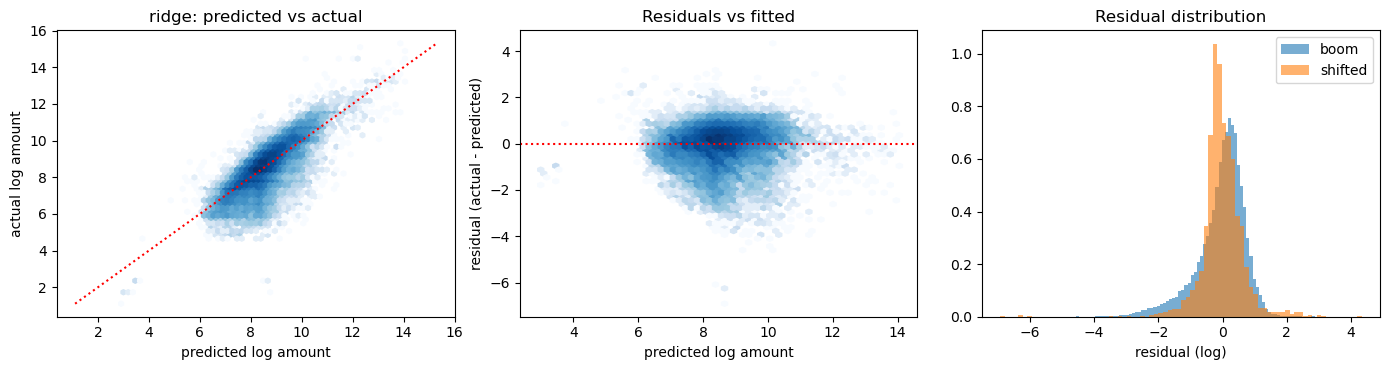

In [4]:
best = "ridge"
p = oof[best][ok]; res = yl - p
d = rp[ok].assign(pred=p, resid=res, regime=np.where(late, "shifted", "boom"))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hexbin(p, yl, gridsize=60, bins="log", cmap="Blues", mincnt=1)
lim = [yl.min(), yl.max()]; axes[0].plot(lim, lim, "r:"); axes[0].set(xlabel="predicted log amount", ylabel="actual log amount", title=f"{best}: predicted vs actual")
axes[1].hexbin(p, res, gridsize=60, bins="log", cmap="Blues", mincnt=1); axes[1].axhline(0, c="r", ls=":")
axes[1].set(xlabel="predicted log amount", ylabel="residual (actual - predicted)", title="Residuals vs fitted")
axes[2].hist(res[~late], bins=80, density=True, alpha=.6, label="boom"); axes[2].hist(res[late], bins=80, density=True, alpha=.6, label="shifted")
axes[2].set(title="Residual distribution", xlabel="residual (log)"); axes[2].legend()
plt.tight_layout(); plt.savefig(FIGURES / "06_residuals.png", dpi=200); plt.show()

In [5]:
bucket = pd.cut(d.duration, [0, 7, 14, 30, 90, 2000], labels=["<=7", "8-14", "15-30", "31-90", ">90"])
hist = np.where(d.n_prev_loans == 0, "no history", np.where(d.n_prev_loans < 5, "1-4 loans", "5+ loans"))
by = pd.concat({
    "term": d.groupby(bucket, observed=True).resid.agg(["size", "mean", lambda r: np.sqrt(np.mean(r ** 2))]),
    "history": d.groupby(hist).resid.agg(["size", "mean", lambda r: np.sqrt(np.mean(r ** 2))]),
    "regime": d.groupby("regime").resid.agg(["size", "mean", lambda r: np.sqrt(np.mean(r ** 2))]),
}).set_axis(["n", "mean residual (bias)", "RMSE (log)"], axis=1)
by.round(3)

n  mean residual (bias)  RMSE (log)
term    <=7         37865                -0.052       0.762
        8-14          488                 0.081       0.459
        15-30         452                 0.205       0.722
        31-90         384                 0.008       0.739
        >90            50                 0.442       1.123
history 1-4 loans    4619                -0.007       0.604
        5+ loans    33034                -0.038       0.762
        no history   1586                -0.331       1.049
regime  boom        36696                -0.048       0.765
        shifted      2543                -0.011       0.654

**Reading the residuals.**
- Predictions rarely go below a log amount of 6 (about 400 KES), while actual loans go far lower. Residuals therefore have a **long negative tail**: sometimes a borrower takes much less than their history suggests. Above the bulk the residuals are centred, so the model does not systematically under-predict big loans.
- Errors are largest for **long-term loans** (above 90 days: RMSE 1.12, under-predicted by 0.44 on average) and **borrowers without history** (RMSE 1.05).
- **First-time borrowers are over-predicted by 0.33 on the log scale**, so the suggested limit is about 40% above what they actually borrowed and repaid. That is the risky direction, in the segment with the highest default rate (Section 3) and the one that makes up all of Ghana. A first-loan cap is needed on top of the model.
- The residual spread is slightly *narrower* in the shifted regime (RMSE 0.65 against 0.77), with almost no bias in either regime, so the loan-size model transfers across time better than the default model.

## 6.3 How NkwaPay would use it

The regression is a **limit**, not an offer: approved applicants (Section 5) receive `min(requested amount, predicted limit)`. Because the model shrinks large amounts, it caps outsized requests from borrowers whose history does not support them. Three caveats:

1. **Selection bias.** We only observe amounts that lenders chose to give and borrowers repaid. We never see whether a declined or capped borrower would have repaid more, so the model reproduces past lending habits.
2. **A point estimate is not a safe limit.** For a conservative limit, fit a lower quantile (for example the 25th percentile with LightGBM's quantile loss) instead of the mean.
3. **Currency and market.** Amounts are Kenyan shillings from a Kenyan market. Converted at 2023 rates they look small for Ghana, and Ghana's products (mostly unseen types, average 36 days) sit where this model's errors are largest. It should not set Ghanaian limits without local data.

In [6]:
pd.DataFrame({n: oof[n] for n in ["ridge", "linreg", "lgbm", "persistence"]}).assign(
    tbl_loan_id=rp.tbl_loan_id, log_amount_target=rp.log_amount_target, fold=fid).to_pickle(DATA_PROCESSED / "oof_regression.pkl")